In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans

In [4]:
df=pd.read_csv("Mall_Customers.csv")
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [6]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

In [7]:
wcss=[]

for k in range(1,11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

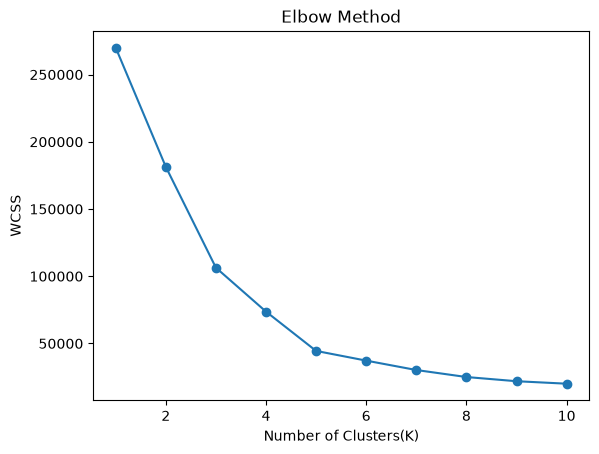

In [10]:
import matplotlib.pyplot as plt
plt.plot(range(1,11),wcss,marker='o')
plt.xlabel('Number of Clusters(K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [11]:
model=KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster']=model.fit_predict(X)

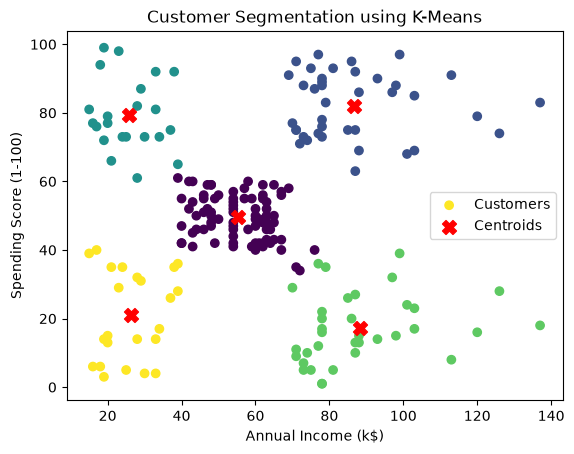

In [13]:
plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis',
    label='Customers'
)

plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=100,
    label='Centroids'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation using K-Means')
plt.legend()
plt.show()